# Experiment 1: the joint $N,\lambda$ limit on a fixed bandwidth interval

This notebook isolates the spectral asymptotics from the separate sample-size limit. It fixes one sample from $N(0,1)$ and the bandwidth interval $[0.05,1]$, then varies only the number $N$ of bandwidth candidates and the similarity scale $\lambda_N$.

$$D_{ij}=\frac12\int (\widehat f_{h_i}-\widehat f_{h_j})^2,\qquad
S_{ij}=e^{-\lambda_ND_{ij}},\qquad
h_{\mathrm{spec},N}=h_{\arg\max_i v_i^{(N)}},$$

where $v^{(N)}$ is the sum-normalized Perron vector of $S$. This is deliberately **not** an AMISE experiment and $n$ never changes.

The $\psi_2$ parametrization is $\psi_2(h)=\log h$, so the bandwidth candidates are geometrically spaced. Every grid has the same endpoints; increasing $N$ only refines the mesh. The admissible sequences satisfy

$$\lambda_N\to\infty,\qquad \lambda_N/N^2\to0,$$

while the remaining sequences deliberately violate one of these conditions.

In [1]:
from __future__ import annotations

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

# Complete supported project API, plus the deliberately separate
# optional Fourier API used for the large matrices.
from kde_tools import *
from kde_tools import __all__ as KDE_PUBLIC_API
from kde_tools.fourier import *
from kde_tools.fourier import __all__ as KDE_FOURIER_API

SEED = 20260902
N_DATA = 200
H_MIN, H_MAX = 0.05, 1.0
BETA = 2.0
N_VALUES = np.array([25, 50, 100, 200, 400, 800])
FFT_HALF_WIDTH = 10.0
FFT_SPATIAL_POINTS = 4096

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)
print(
    f"Imported {len(KDE_PUBLIC_API)} public KDE helpers and "
    f"{len(KDE_FOURIER_API)} optional Fourier helpers."
)

Imported 31 public KDE helpers and 4 optional Fourier helpers.


In [2]:
rng = np.random.default_rng(SEED)
samples = rng.normal(loc=0.0, scale=1.0, size=N_DATA)

endpoint_check = pd.DataFrame({
    "N": N_VALUES,
    "first h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[0]
        for N in N_VALUES
    ],
    "last h": [
        bandwidth_grid_linear_in_psi_beta(
            H_MIN, H_MAX, BETA, int(N)
        )[-1]
        for N in N_VALUES
    ],
    "Delta log(h)": [
        np.log(H_MAX / H_MIN) / (N - 1) for N in N_VALUES
    ],
})

print(
    f"Fixed sample: n={N_DATA}, seed={SEED}, "
    f"mean={samples.mean():.4f}, sd={samples.std(ddof=1):.4f}"
)
display(endpoint_check)

Fixed sample: n=200, seed=20260902, mean=-0.0844, sd=0.9469


,N,first h,last h,Delta log(h)
0,25,0.05,1.0,0.124822
1,50,0.05,1.0,0.061137
2,100,0.05,1.0,0.030260
3,200,0.05,1.0,0.015054
4,400,0.05,1.0,0.007508
5,800,0.05,1.0,0.003749


## Continuous large-$N$, large-$\lambda$ prediction

Write $\psi=\log h$. Locally, beta-2 divergence has the quadratic expansion

$$D_2(\widehat f_h,\widehat f_{he^\delta})
=a(h)\delta^2+o(\delta^2),\qquad
a(h)=\frac12\left\|\partial_\psi\widehat f_h\right\|_2^2.$$

The localized continuous kernel has row width proportional to $a(h)^{-1/2}$, so its Perron mass concentrates at

$$h_\infty=\operatorname*{arg\,min}_{h\in[0.05,1]}a(h).$$

For Gaussian KDEs, this coefficient can be evaluated without numerical differentiation. If $d_{rs}=(X_r-X_s)^2$, $q=2h^2$, and $g_q(d)=(2\pi q)^{-1/2}e^{-d/(2q)}$, then

$$a(h)=2h^4\frac1{n^2}\sum_{r,s}g_q(d_{rs})
\left(\frac{3}{4q^2}-\frac{3d_{rs}}{2q^3}
+\frac{d_{rs}^2}{4q^4}\right).$$

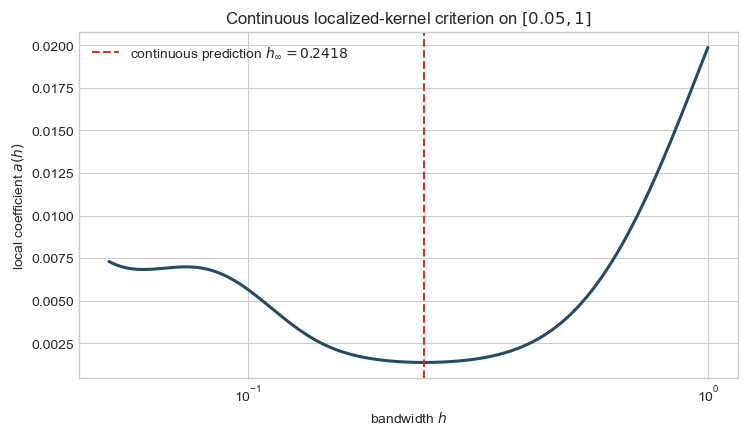

Continuous-limit prediction: h_infinity = 0.24175622


In [3]:
squared_sample_differences = (
    samples[:, None] - samples[None, :]
) ** 2

def local_beta2_log_metric(
    bandwidth: float,
    squared_differences: np.ndarray,
) -> float:
    """Exact coefficient of (Delta log h)^2 for this KDE family."""
    h = float(bandwidth)
    q = 2.0 * h**2
    d = np.asarray(squared_differences, dtype=float)
    overlap = np.exp(-d / (2.0 * q)) / np.sqrt(2.0 * np.pi * q)
    second_q_factor = (
        3.0 / (4.0 * q**2)
        - 3.0 * d / (2.0 * q**3)
        + d**2 / (4.0 * q**4)
    )
    return float(
        2.0 * h**4 * np.mean(overlap * second_q_factor)
    )

continuous_minimum = minimize_scalar(
    lambda h: local_beta2_log_metric(
        h, squared_sample_differences
    ),
    bounds=(H_MIN, H_MAX),
    method="bounded",
    options={"xatol": 1e-12},
)
if not continuous_minimum.success:
    raise RuntimeError(continuous_minimum.message)

h_infinity = float(continuous_minimum.x)
metric_grid = np.geomspace(H_MIN, H_MAX, 600)
metric_values = np.array([
    local_beta2_log_metric(h, squared_sample_differences)
    for h in metric_grid
])

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(
    metric_grid, metric_values,
    color="#244c66", linewidth=2.2
)
ax.axvline(
    h_infinity, color="#c23b22", linestyle="--",
    label=rf"continuous prediction $h_\infty={h_infinity:.4f}$",
)
ax.set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel=r"local coefficient $a(h)$",
    title=r"Continuous localized-kernel criterion on $[0.05,1]$",
)
ax.legend()
plt.show()
print(f"Continuous-limit prediction: h_infinity = {h_infinity:.8f}")

## Numerical method and validation

The project already contains an exact analytic beta-2 calculation. Its cost grows like $N^2n^2$, so the full sweep uses the existing Fourier reconstruction and one matrix product per $N$. The next cell checks that approximation against the exact helper on the smallest grid.

In [4]:
validation_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BETA, grid_size=25
)
validation_exact = beta2_divergence_matrix(
    samples, validation_grid
)
validation_fft = beta2_divergence_matrix_fft(
    samples, validation_grid,
    half_width=FFT_HALF_WIDTH,
    spatial_points=FFT_SPATIAL_POINTS,
)
validation_abs_error = np.max(
    np.abs(validation_fft - validation_exact)
)
validation_rel_error = (
    validation_abs_error / np.max(validation_exact)
)

print(f"maximum absolute D2 error: {validation_abs_error:.3e}")
print(f"error relative to max(D2): {validation_rel_error:.3e}")
if validation_rel_error > 2e-5:
    warnings.warn(
        "Increase FFT_HALF_WIDTH or FFT_SPATIAL_POINTS."
    )

maximum absolute D2 error: 3.331e-16
error relative to max(D2): 1.675e-14


In [5]:
LAMBDA_RULES = {
    r"$N^{1/2}$ (admissible)": lambda N: N**0.5,
    r"$N$ (admissible)": lambda N: float(N),
    r"$N^{3/2}$ (admissible)": lambda N: N**1.5,
    r"$1$ (not localized)": lambda N: 1.0,
    r"$N^2$ (mesh-scale)": lambda N: float(N**2),
    r"$N^3$ (collapse)": lambda N: float(N**3),
}
REGIME_ORDER = list(LAMBDA_RULES)
REGIME_COLORS = dict(zip(
    REGIME_ORDER,
    ["#0072B2", "#009E73", "#CC79A7",
     "#E69F00", "#7A7A7A", "#D55E00"],
))

rows = []
largest_grid_vectors = {}
start_time = time.perf_counter()

for N in N_VALUES:
    N = int(N)
    h_grid = bandwidth_grid_linear_in_psi_beta(
        h_min=H_MIN, h_max=H_MAX,
        beta=BETA, grid_size=N,
    )
    divergence = beta2_divergence_matrix_fft(
        samples, h_grid,
        half_width=FFT_HALF_WIDTH,
        spatial_points=FFT_SPATIAL_POINTS,
    )
    reference_index = nearest_bandwidth_grid_index(
        h_infinity, h_grid
    )
    neighbor_left = min(reference_index, N - 2)
    neighbor_D = divergence[
        neighbor_left, neighbor_left + 1
    ]
    endpoint_D = divergence[0, -1]

    for regime, lambda_rule in LAMBDA_RULES.items():
        lambda_value = float(lambda_rule(N))
        similarity = np.exp(-lambda_value * divergence)
        np.fill_diagonal(similarity, 1.0)
        vector = perron_vector(similarity)
        selected_index = int(np.argmax(vector))
        selected_h = float(h_grid[selected_index])

        rows.append({
            "N": N,
            "regime": regime,
            "lambda": lambda_value,
            "lambda_over_N2": lambda_value / N**2,
            "selected_index": selected_index,
            "selected_h": selected_h,
            "absolute_error": abs(selected_h - h_infinity),
            "global_exponent": lambda_value * endpoint_D,
            "neighbor_exponent": lambda_value * neighbor_D,
            "neighbor_similarity": np.exp(
                -lambda_value * neighbor_D
            ),
        })
        if N == int(N_VALUES[-1]):
            largest_grid_vectors[regime] = (
                h_grid.copy(), vector.copy()
            )

results = pd.DataFrame(rows)
results["regime"] = pd.Categorical(
    results["regime"],
    categories=REGIME_ORDER,
    ordered=True,
)
results = results.sort_values(
    ["regime", "N"]
).reset_index(drop=True)

elapsed = time.perf_counter() - start_time
print(
    f"Completed {len(results)} selector runs "
    f"in {elapsed:.2f} seconds."
)
display(results.pivot(
    index="N", columns="regime", values="selected_h"
).round(6))

Completed 36 selector runs in 2.65 seconds.


regime,$N^{1/2}$ (admissible),$N$ (admissible),$N^{3/2}$ (admissible),$1$ (not localized),$N^2$ (mesh-scale),$N^3$ (collapse)
N,,,,,,
25,0.287015,0.253335,0.223607,0.287015,0.253335,0.253335
50,0.260534,0.245083,0.230548,0.276959,0.245083,0.245083
100,0.264098,0.233990,0.241179,0.264098,0.241179,0.241179
200,0.257985,0.232183,0.242909,0.261898,0.242909,0.242909
400,0.255004,0.236560,0.241948,0.262779,0.241948,0.241948
800,0.251639,0.239667,0.242378,0.262234,0.242378,0.241471


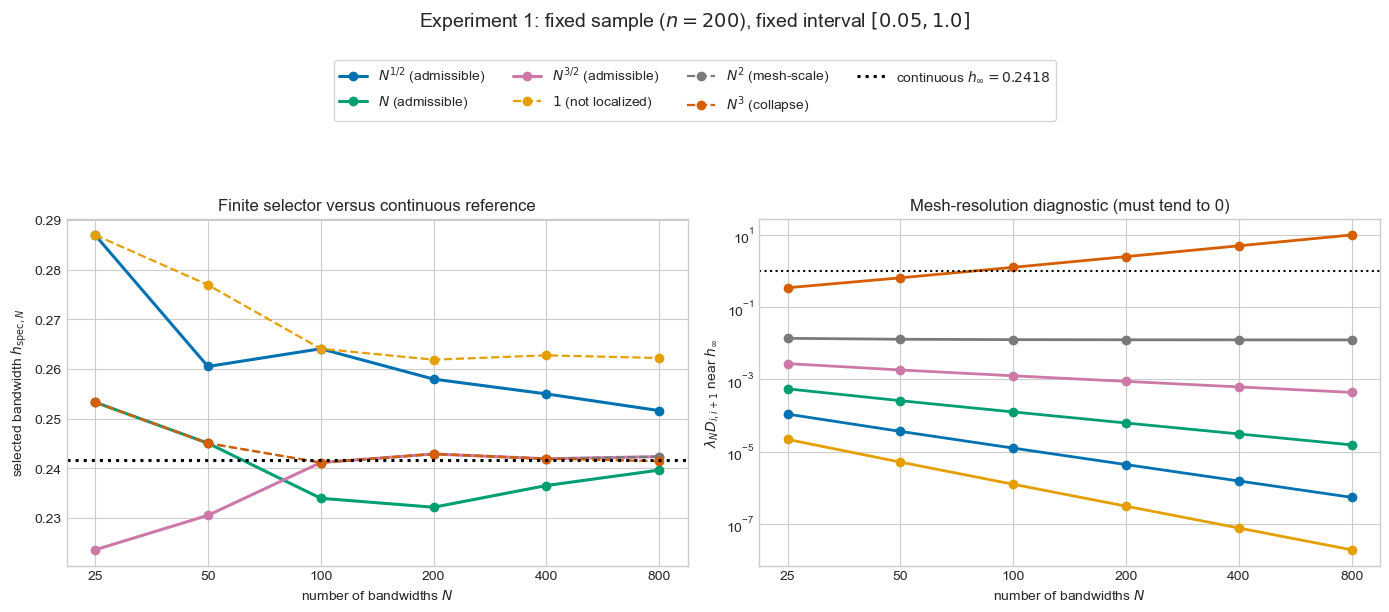

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))

for regime in REGIME_ORDER:
    subset = results[results["regime"] == regime]
    admissible = "admissible" in regime
    axes[0].plot(
        subset["N"], subset["selected_h"],
        marker="o",
        linewidth=2.2 if admissible else 1.6,
        linestyle="-" if admissible else "--",
        color=REGIME_COLORS[regime],
        label=regime,
    )
    axes[1].plot(
        subset["N"], subset["neighbor_exponent"],
        marker="o", linewidth=2.0,
        color=REGIME_COLORS[regime],
        label=regime,
    )

axes[0].axhline(
    h_infinity, color="black",
    linestyle=":", linewidth=2.2,
    label=rf"continuous $h_\infty={h_infinity:.4f}$",
)
axes[0].set(
    xlabel=r"number of bandwidths $N$",
    ylabel=r"selected bandwidth $h_{\mathrm{spec},N}$",
    title="Finite selector versus continuous reference",
)
axes[1].axhline(
    1.0, color="black", linestyle=":", linewidth=1.5
)
axes[1].set(
    yscale="log",
    xlabel=r"number of bandwidths $N$",
    ylabel=r"$\lambda_ND_{i,i+1}$ near $h_\infty$",
    title="Mesh-resolution diagnostic (must tend to 0)",
)
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(N_VALUES, labels=N_VALUES)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="upper center",
    bbox_to_anchor=(0.5, 0.91), ncol=4, frameon=True
)
fig.suptitle(
    rf"Experiment 1: fixed sample ($n={N_DATA}$), "
    rf"fixed interval $[{H_MIN},{H_MAX}]$",
    y=0.98, fontsize=14,
)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.76))
plt.show()

,regime,lambda,lambda_over_N2,selected_h,absolute_error,global_exponent,neighbor_exponent,neighbor_similarity
5,$N^{1/2}$ (admissible),2.828427e+01,0.000044,0.251638,0.009882,5.625543e-01,5.000000e-07,1.000000
11,$N$ (admissible),8.000000e+02,0.001250,0.239667,0.002089,1.591144e+01,1.540000e-05,0.999985
17,$N^{3/2}$ (admissible),2.262742e+04,0.035355,0.242378,0.000622,4.500435e+02,4.356000e-04,0.999564
23,$1$ (not localized),1.000000e+00,0.000002,0.262234,0.020478,1.988930e-02,0.000000e+00,1.000000
29,$N^2$ (mesh-scale),6.400000e+05,1.000000,0.242378,0.000622,1.272915e+04,1.232040e-02,0.987755
35,$N^3$ (collapse),5.120000e+08,800.000000,0.241471,0.000285,1.018332e+07,9.856331e+00,0.000052


At N=800, the admissible selectors span 0.011971 in bandwidth.


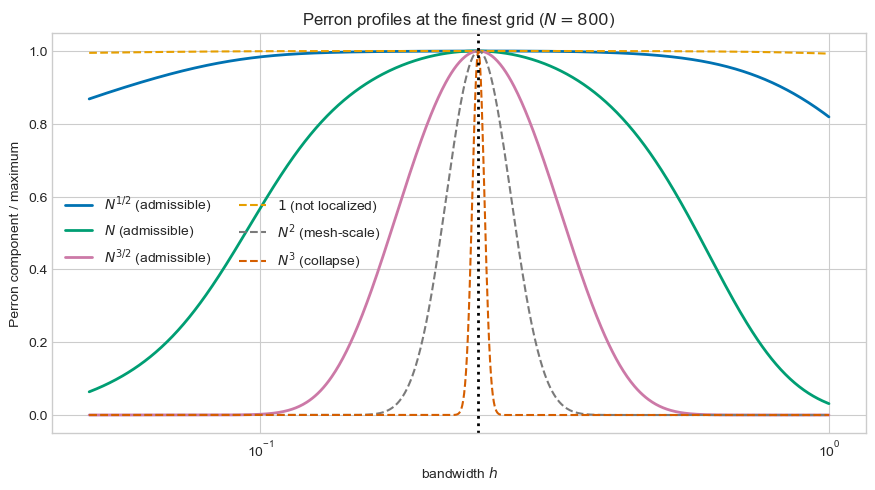

In [7]:
final_N = int(N_VALUES[-1])
final_diagnostics = results[
    results["N"] == final_N
][[
    "regime", "lambda", "lambda_over_N2",
    "selected_h", "absolute_error",
    "global_exponent", "neighbor_exponent",
    "neighbor_similarity",
]].copy()

admissible_final = final_diagnostics[
    final_diagnostics["regime"].isin(REGIME_ORDER[:3])
]
admissible_spread = (
    admissible_final["selected_h"].max()
    - admissible_final["selected_h"].min()
)
display(final_diagnostics.round(7))
print(
    f"At N={final_N}, the admissible selectors span "
    f"{admissible_spread:.6f} in bandwidth."
)

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for regime in REGIME_ORDER:
    h_grid, vector = largest_grid_vectors[regime]
    admissible = "admissible" in regime
    ax.plot(
        h_grid, vector / vector.max(),
        color=REGIME_COLORS[regime],
        linewidth=2.0 if admissible else 1.5,
        linestyle="-" if admissible else "--",
        label=regime,
    )
ax.axvline(
    h_infinity, color="black",
    linestyle=":", linewidth=2.0
)
ax.set(
    xscale="log",
    xlabel=r"bandwidth $h$",
    ylabel="Perron component / maximum",
    title=rf"Perron profiles at the finest grid ($N={final_N}$)",
)
ax.legend(ncol=2)
plt.show()

## Interpretation

- The three admissible sequences approach the same sample-conditional continuous reference, although $N^{1/2}$ localizes more slowly than $N$ and $N^{3/2}$.
- With $\lambda_N=1$, the kernel never becomes globally localized. Its selector can stabilize, but not at the large-$\lambda$ criterion.
- With $\lambda_N=N^2$, the neighbor exponent remains at mesh scale instead of tending to zero. The selected bandwidth may look plausible, but it is a discretized-kernel limit rather than the target continuous local limit.
- With $\lambda_N=N^3$, neighboring similarities collapse toward zero and the matrix approaches the identity. The Perron eigenvalue becomes nearly degenerate, so an apparently accurate argmax is not evidence of the desired limit.

This is why the mesh diagnostic and final table are part of Experiment 1: the bandwidth path alone cannot verify the joint-limit assumptions.

## Scope and reproducibility

Change SEED or N_DATA only for a robustness rerun; keep them fixed within a run. The experiment intentionally makes no comparison with $h_{\mathrm{AMISE}}$ and no claim about $n\to\infty$. Those belong to Experiment 2.